In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./car_fuel_efficiency_2026.csv")

In [26]:
#EDA
df.describe()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.000000,10000.00000,10000.000000,10000.000000,9123.000000,10000.000000,9736.000000,10000.000000
mean,1999.549500,3.50400,2268.807000,6.035200,254.446016,4286.754000,18.888044,29.997700
std,14.207925,0.95209,183.447355,0.542578,22.844613,266.212491,1.279543,2.930245
min,1975.000000,2.00000,1590.000000,4.000000,171.000000,3320.000000,14.000000,19.800000
25%,1987.000000,3.00000,2150.000000,6.000000,239.000000,4110.000000,18.000000,28.000000
50%,2000.000000,4.00000,2270.000000,6.000000,254.000000,4280.000000,18.900000,30.000000
75%,2012.000000,4.00000,2390.000000,6.000000,270.000000,4470.000000,19.700000,31.900000
max,2024.000000,5.00000,3110.000000,8.000000,334.000000,5460.000000,23.800000,41.200000


In [27]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

model_year
[2006 2008 1996 1989 1994]
50

origin
<StringArray>
['Europe', 'Asia', 'USA']
Length: 3, dtype: str
3

fuel_type
<StringArray>
['Gasoline', 'Diesel', 'Hybrid']
Length: 3, dtype: str
3

drivetrain
<StringArray>
['Front-wheel drive', 'Rear-wheel drive', 'All-wheel drive']
Length: 3, dtype: str
3

num_doors
[4 5 3 2]
4

engine_displacement
[2180 2390 2320 2130 2580]
127

num_cylinders
[6 7 5 8 4]
5

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

acceleration
[ nan 17.3 18.7 17.5 18.8]
93

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



<Axes: ylabel='Count'>

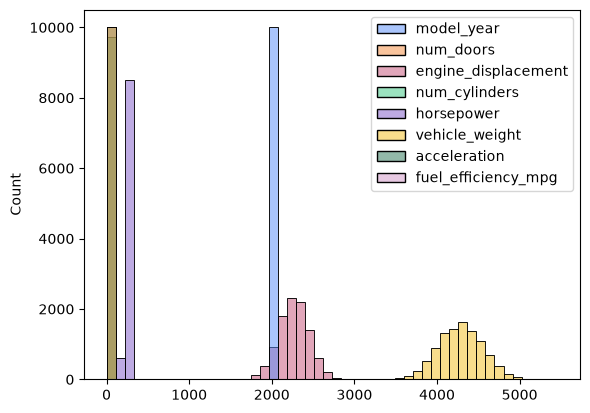

In [28]:
%matplotlib inline

sns.histplot(df, bins=50)

In [29]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [30]:
df.tail(5)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2
9999,2011,USA,Diesel,Front-wheel drive,4,2380,6,295.0,4370,17.6,30.2


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


# Q1

In [32]:
missing_values = df.columns[df.isnull().any()].tolist()
print("Question 1:",missing_values)

Question 1: ['horsepower', 'acceleration']


# Q2

In [33]:
hp_median = df['horsepower'].dropna().median()
print("Question 2:",hp_median)

Question 2: 254.0


# Q3

In [34]:
n = len(df)
n_val = int(n*0.2)
n_test = int(n*0.2)
n_train = n - n_val - n_test

n, n_val, n_test, n_train

(10000, 2000, 2000, 6000)

In [35]:
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

df.iloc[idx[:5]]

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
6252,2015,USA,Diesel,Front-wheel drive,3,1900,5,239.0,3790,20.3,32.5
4684,1992,USA,Gasoline,All-wheel drive,4,2000,6,224.0,4380,21.8,29.1
1731,2022,USA,Hybrid,Front-wheel drive,3,2330,6,286.0,4090,17.8,34.1
4742,1997,Asia,Gasoline,Front-wheel drive,5,2300,6,NaN,4150,19.9,30.6
4521,2001,USA,Gasoline,Front-wheel drive,4,2340,6,269.0,4400,18.6,30.7


In [53]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res += xi[j] * w[j]
    return res

In [ ]:
def train_linear_regression(X, y):
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full, w

In [38]:
hp = np.round(np.mean(df_train['horsepower']),2)
acc = np.round(np.mean(df_train['acceleration']),2)

print(missing_values)

mean

['horsepower', 'acceleration']


[np.float64(254.46), np.float64(18.89)]

In [42]:
new_df = df.fillna({'horsepower': hp, 'acceleration': acc})

new_df.columns[new_df.isnull().any()].tolist()

[]

In [51]:
base = df_train.columns.tolist()
X_train = df_train[base].fillna(0).values

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
6252,2015,USA,Diesel,Front-wheel drive,3,1900,5,239.0,3790,20.3,32.5
4684,1992,USA,Gasoline,All-wheel drive,4,2000,6,224.0,4380,21.8,29.1
1731,2022,USA,Hybrid,Front-wheel drive,3,2330,6,286.0,4090,17.8,34.1
4742,1997,Asia,Gasoline,Front-wheel drive,5,2300,6,0.0,4150,19.9,30.6
4521,2001,USA,Gasoline,Front-wheel drive,4,2340,6,269.0,4400,18.6,30.7
...,...,...,...,...,...,...,...,...,...,...,...
7895,2018,Asia,Gasoline,Rear-wheel drive,4,2280,6,242.0,4590,20.5,29.8
9590,1984,Europe,Gasoline,Front-wheel drive,2,2300,6,0.0,4240,18.1,25.1
7288,1989,USA,Gasoline,Front-wheel drive,3,2240,6,255.0,4190,17.2,27.7
278,2020,Europe,Gasoline,Rear-wheel drive,5,2430,6,254.0,4280,18.4,31.6


In [52]:
w0, w = train_linear_regression(X_train, y_train)

NameError: name 'train_linear_regression' is not defined